# Cell 1 — Install & imports

In [1]:
!pip install -q PyWavelets mne

import numpy as np
import pandas as pd
import mne
from scipy.stats import kurtosis as sp_kurtosis
from scipy.signal import welch, stft
import pywt
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

print('Imports OK')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 83.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
Imports OK


# Cell 2 — Reconnect paths, load segments and manifest

In [2]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = Path('/content/drive/MyDrive/PD_EEG_Thesis_Features_v2')
SEG_DIR      = PROJECT_ROOT / 'data' / 'segments'
REGION_DIR   = PROJECT_ROOT / 'data' / 'regional_features'
REGION_DIR.mkdir(parents=True, exist_ok=True)

seg_d = np.load(str(SEG_DIR / 'segments_all.npz'))
X_raw, y, subjects = seg_d['X'], seg_d['y'], seg_d['subjects']
print(f'Loaded segments: {X_raw.shape}   PD={int(y.sum())}  Control={int((y==0).sum())}')

manifest = pd.read_csv(PROJECT_ROOT / 'manifest.csv')

Mounted at /content/drive
Loaded segments: (3915, 60, 3000)   PD=2549  Control=1366


# Cell 3 — Recover canonical 60-channel order (must match segmentation order exactly)

In [3]:
print('Recovering canonical channel order...')
common_chs = None
for _, row in manifest.iterrows():
    raw_check = mne.io.read_raw_edf(row['edf_path'], preload=False, verbose=False)
    chs = set(raw_check.ch_names)
    common_chs = chs if common_chs is None else common_chs & chs

ref_raw = mne.io.read_raw_edf(manifest.iloc[0]['edf_path'], preload=False, verbose=False)
CHANNEL_NAMES = [ch for ch in ref_raw.ch_names if ch in common_chs]
assert len(CHANNEL_NAMES) == X_raw.shape[1], 'Channel count mismatch — order may not match segmentation!'
print(f'Recovered {len(CHANNEL_NAMES)} channels, confirmed matching segments_all.npz shape.')

Recovering canonical channel order...
Recovered 60 channels, confirmed matching segments_all.npz shape.


# Cell 4 — ROI channel groups and index mapping

In [4]:
ROI_GROUPS = {
    'Left_Frontal':  ['Fp1', 'AF7', 'AF3', 'F7', 'F5', 'F3', 'F1', 'FC5', 'FC3', 'FC1'],
    'Right_Frontal': ['Fp2', 'AF8', 'AF4', 'F8', 'F6', 'F4', 'F2', 'FC6', 'FC4', 'FC2'],
    'Left_Parietal':  ['CP5', 'CP3', 'CP1', 'P7', 'P5', 'P3', 'P1', 'PO7', 'PO3'],
    'Right_Parietal': ['CP6', 'CP4', 'CP2', 'P8', 'P6', 'P4', 'P2', 'PO8', 'PO4'],
}

region_indices = {}
for region, chs in ROI_GROUPS.items():
    available = [ch for ch in chs if ch in CHANNEL_NAMES]
    missing = [ch for ch in chs if ch not in CHANNEL_NAMES]
    if missing:
        print(f'⚠️  {region}: missing channels {missing} — proceeding with {len(available)}/{len(chs)}')
    region_indices[region] = [CHANNEL_NAMES.index(ch) for ch in available]
    print(f'{region}: {len(region_indices[region])} channels')

Left_Frontal: 10 channels
Right_Frontal: 10 channels
⚠️  Left_Parietal: missing channels ['PO3'] — proceeding with 8/9
Left_Parietal: 8 channels
⚠️  Right_Parietal: missing channels ['PO4'] — proceeding with 8/9
Right_Parietal: 8 channels


# Cell 5 — Parameters and the 17 selected-feature extraction functions (identical formulas to Notebook 3)

In [5]:
FS = 500
N_TIMESTEPS = 6
SUBWIN_SAMPLES = 500
BANDS = {'theta': (4,8), 'alpha': (8,13), 'beta': (13,30), 'gamma': (30,45)}
WAVELET, WAVELET_LEVEL = 'db4', 3

SELECTED_FEATURE_NAMES = [
    'hjorth_complexity', 'zero_crossing_rate', 'hjorth_mobility', 'line_length', 'kurtosis', 'peak_to_peak',
    'beta_power', 'theta_beta_ratio', 'theta_power', 'spectral_entropy', 'alpha_beta_ratio',
    'spectral_centroid', 'spectral_edge_95', 'gamma_power',
    'stft_low_band_power', 'wavelet_entropy', 'teager_energy',
]

def zscore_window(window):
    std = window.std()
    if std < 1e-8: std = 1e-8
    return (window - window.mean()) / std

def compute_adjacency(window, threshold=0.3):
    corr = np.nan_to_num(np.corrcoef(window), nan=0.0)
    adj  = np.where(corr >= threshold, corr, 0.0).astype(np.float32)
    np.fill_diagonal(adj, 0.0)
    return adj

def extract_selected_features(sw, fs=FS):
    """sw: (n_ch, 500) z-scored sub-window -> dict of the 17 selected features, (n_ch,) each."""
    n_ch = sw.shape[0]
    std = sw.std(axis=1)
    zero_var_mask = std < 1e-8

    # Time domain
    d1 = np.diff(sw, axis=1); d2 = np.diff(d1, axis=1)
    var0, var1, var2 = np.var(sw, axis=1), np.var(d1, axis=1), np.var(d2, axis=1)
    mobility   = np.sqrt(var1 / (var0 + 1e-12))
    complexity = np.sqrt(var2 / (var1 + 1e-12)) / (mobility + 1e-12)
    zcr  = np.mean(np.diff(np.sign(sw), axis=1) != 0, axis=1)
    line_length = np.sum(np.abs(np.diff(sw, axis=1)), axis=1)
    ptp  = np.ptp(sw, axis=1)
    kurt = np.where(zero_var_mask, 0.0, sp_kurtosis(sw, axis=1))
    kurt = np.nan_to_num(kurt, nan=0.0)

    # Frequency domain
    freqs, psd = welch(sw, fs=fs, nperseg=min(250, sw.shape[1]), axis=1)
    total_power = np.sum(psd, axis=1) + 1e-12

    def band_power(lo, hi):
        mask = (freqs >= lo) & (freqs < hi)
        return np.sum(psd[:, mask], axis=1) / total_power

    theta_p, alpha_p, beta_p, gamma_p = (band_power(*BANDS[b]) for b in ['theta','alpha','beta','gamma'])
    theta_beta = np.clip(theta_p / (beta_p + 1e-6), 0, 20)
    alpha_beta = np.clip(alpha_p / (beta_p + 1e-6), 0, 20)

    cumsum = np.cumsum(psd, axis=1) / total_power[:, None]
    sef95 = np.array([freqs[np.searchsorted(cumsum[i], 0.95)] if np.any(cumsum[i] >= 0.95) else freqs[-1]
                      for i in range(n_ch)])
    psd_norm = psd / total_power[:, None]
    spec_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12), axis=1) / np.log2(psd.shape[1])
    spec_centroid = np.sum(freqs[None, :] * psd, axis=1) / total_power

    # Time-frequency
    stft_low_power, wav_entropy, teager = [], [], []
    for ch in range(n_ch):
        f, t, Zxx = stft(sw[ch], fs=fs, nperseg=min(128, len(sw[ch])))
        mag = np.abs(Zxx)
        total_mag = np.sum(mag) + 1e-12
        low_mask = f < 13
        stft_low_power.append(np.sum(mag[low_mask, :]) / total_mag)

        coeffs = pywt.wavedec(sw[ch], WAVELET, level=WAVELET_LEVEL)
        e = np.array([np.sum(c**2) for c in coeffs])
        e = e / (e.sum() + 1e-12)
        wav_entropy.append(-np.sum(e * np.log2(e + 1e-12)))

        x = sw[ch]
        tkeo = x[1:-1]**2 - x[:-2]*x[2:]
        teager.append(np.mean(tkeo))

    return {
        'hjorth_complexity': complexity, 'zero_crossing_rate': zcr, 'hjorth_mobility': mobility,
        'line_length': line_length, 'kurtosis': kurt, 'peak_to_peak': ptp,
        'beta_power': beta_p, 'theta_beta_ratio': theta_beta, 'theta_power': theta_p,
        'spectral_entropy': spec_entropy, 'alpha_beta_ratio': alpha_beta,
        'spectral_centroid': spec_centroid, 'spectral_edge_95': sef95, 'gamma_power': gamma_p,
        'stft_low_band_power': np.array(stft_low_power), 'wavelet_entropy': np.array(wav_entropy),
        'teager_energy': np.array(teager),
    }

print('Extraction function ready — computes the same 17 features as Notebook 3, for any channel subset.')

Extraction function ready — computes the same 17 features as Notebook 3, for any channel subset.


# Cell 6 — Extract features and build graphs, per region (z-scored within each region's own channels)

In [6]:
n_samples = X_raw.shape[0]

for region_name, ch_idx in region_indices.items():
    print(f'\n{"="*50}\n{region_name}  ({len(ch_idx)} channels)\n{"="*50}')

    X_region = X_raw[:, ch_idx, :]   # (n_samples, n_region_ch, 3000)
    n_ch = len(ch_idx)

    node_features = np.zeros((n_samples, N_TIMESTEPS, n_ch, len(SELECTED_FEATURE_NAMES)), dtype=np.float32)
    adjacency = np.zeros((n_samples, n_ch, n_ch), dtype=np.float32)

    for i in range(n_samples):
        w = zscore_window(X_region[i])   # z-scored using ONLY this region's channels
        adjacency[i] = compute_adjacency(w)
        for t in range(N_TIMESTEPS):
            sw = w[:, t*SUBWIN_SAMPLES:(t+1)*SUBWIN_SAMPLES]
            feats = extract_selected_features(sw)
            node_features[i, t] = np.stack([feats[name] for name in SELECTED_FEATURE_NAMES], axis=1)
        if (i+1) % 1000 == 0:
            print(f'  Processed {i+1}/{n_samples}')

    # Same percentile clipping safeguard as Notebook 3
    for f_idx in range(len(SELECTED_FEATURE_NAMES)):
        p1, p99 = np.percentile(node_features[:,:,:,f_idx], [1, 99])
        node_features[:,:,:,f_idx] = np.clip(node_features[:,:,:,f_idx], p1, p99)

    np.savez_compressed(str(REGION_DIR / f'features_{region_name}.npz'),
                        node_features=node_features, adjacency=adjacency, y=y, subjects=subjects,
                        channel_names=np.array([CHANNEL_NAMES[i] for i in ch_idx], dtype=object))
    print(f'Saved: node_features {node_features.shape}, adjacency {adjacency.shape}')

print('\n\nAll 4 regions extracted and saved.')


Left_Frontal  (10 channels)
  Processed 1000/3915
  Processed 2000/3915
  Processed 3000/3915
Saved: node_features (3915, 6, 10, 17), adjacency (3915, 10, 10)

Right_Frontal  (10 channels)
  Processed 1000/3915
  Processed 2000/3915
  Processed 3000/3915
Saved: node_features (3915, 6, 10, 17), adjacency (3915, 10, 10)

Left_Parietal  (8 channels)
  Processed 1000/3915
  Processed 2000/3915
  Processed 3000/3915
Saved: node_features (3915, 6, 8, 17), adjacency (3915, 8, 8)

Right_Parietal  (8 channels)
  Processed 1000/3915
  Processed 2000/3915
  Processed 3000/3915
Saved: node_features (3915, 6, 8, 17), adjacency (3915, 8, 8)


All 4 regions extracted and saved.


# Cell 7 — Verification summary

In [7]:
print('=== Regional Feature Extraction Summary ===\n')
for region_name in ROI_GROUPS:
    d = np.load(str(REGION_DIR / f'features_{region_name}.npz'), allow_pickle=True)
    print(f'{region_name}: node_features={d["node_features"].shape}  '
          f'channels={list(d["channel_names"])}')

=== Regional Feature Extraction Summary ===

Left_Frontal: node_features=(3915, 6, 10, 17)  channels=['Fp1', 'AF7', 'AF3', 'F7', 'F5', 'F3', 'F1', 'FC5', 'FC3', 'FC1']
Right_Frontal: node_features=(3915, 6, 10, 17)  channels=['Fp2', 'AF8', 'AF4', 'F8', 'F6', 'F4', 'F2', 'FC6', 'FC4', 'FC2']
Left_Parietal: node_features=(3915, 6, 8, 17)  channels=['CP5', 'CP3', 'CP1', 'P7', 'P5', 'P3', 'P1', 'PO7']
Right_Parietal: node_features=(3915, 6, 8, 17)  channels=['CP6', 'CP4', 'CP2', 'P8', 'P6', 'P4', 'P2', 'PO8']


# Cell 8 — 3D scalp map with all four regions highlighted

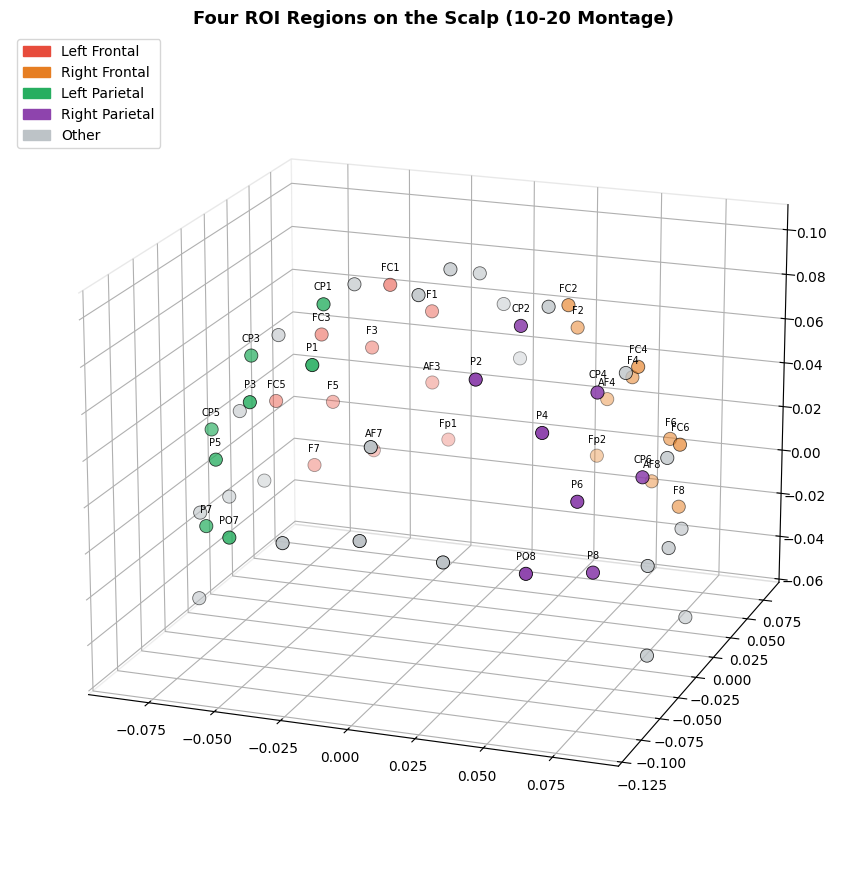

In [8]:
!pip install -q mne
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
%matplotlib inline

montage = mne.channels.make_standard_montage('standard_1020')
positions_3d = montage.get_positions()['ch_pos']

REGION_COLORS = {'Left_Frontal': '#e74c3c', 'Right_Frontal': '#e67e22',
                 'Left_Parietal': '#27ae60', 'Right_Parietal': '#8e44ad', 'Other': '#bdc3c7'}

coords, colors, labels = [], [], []
for ch in CHANNEL_NAMES:
    if ch not in positions_3d:
        continue
    coords.append(positions_3d[ch])
    region = next((r for r, idxs in region_indices.items() if CHANNEL_NAMES.index(ch) in idxs), 'Other')
    colors.append(REGION_COLORS[region])
    labels.append(ch)

coords = np.array(coords)
xs, ys, zs = coords[:,0], coords[:,1], coords[:,2]

fig = plt.figure(figsize=(11, 9))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(xs, ys, zs, c=colors, s=90, edgecolor='black', linewidth=0.6)
for i, lbl in enumerate(labels):
    if colors[i] != REGION_COLORS['Other']:
        ax.text(xs[i], ys[i], zs[i]+0.006, lbl, fontsize=7, ha='center')

for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
    axis.pane.set_facecolor((1,1,1,0)); axis.pane.set_edgecolor('lightgray')
ax.view_init(elev=18, azim=-70)
ax.set_title('Four ROI Regions on the Scalp (10-20 Montage)', fontsize=13, fontweight='bold')

legend_handles = [mpatches.Patch(color=c, label=r.replace('_',' ')) for r, c in REGION_COLORS.items()]
ax.legend(handles=legend_handles, loc='upper left')
plt.tight_layout()
plt.savefig(str(REGION_DIR / 'regions_3d_scalp.png'), dpi=140, bbox_inches='tight')
plt.show()

# Cell 9 — Per-region average connectivity heatmaps, PD vs Control

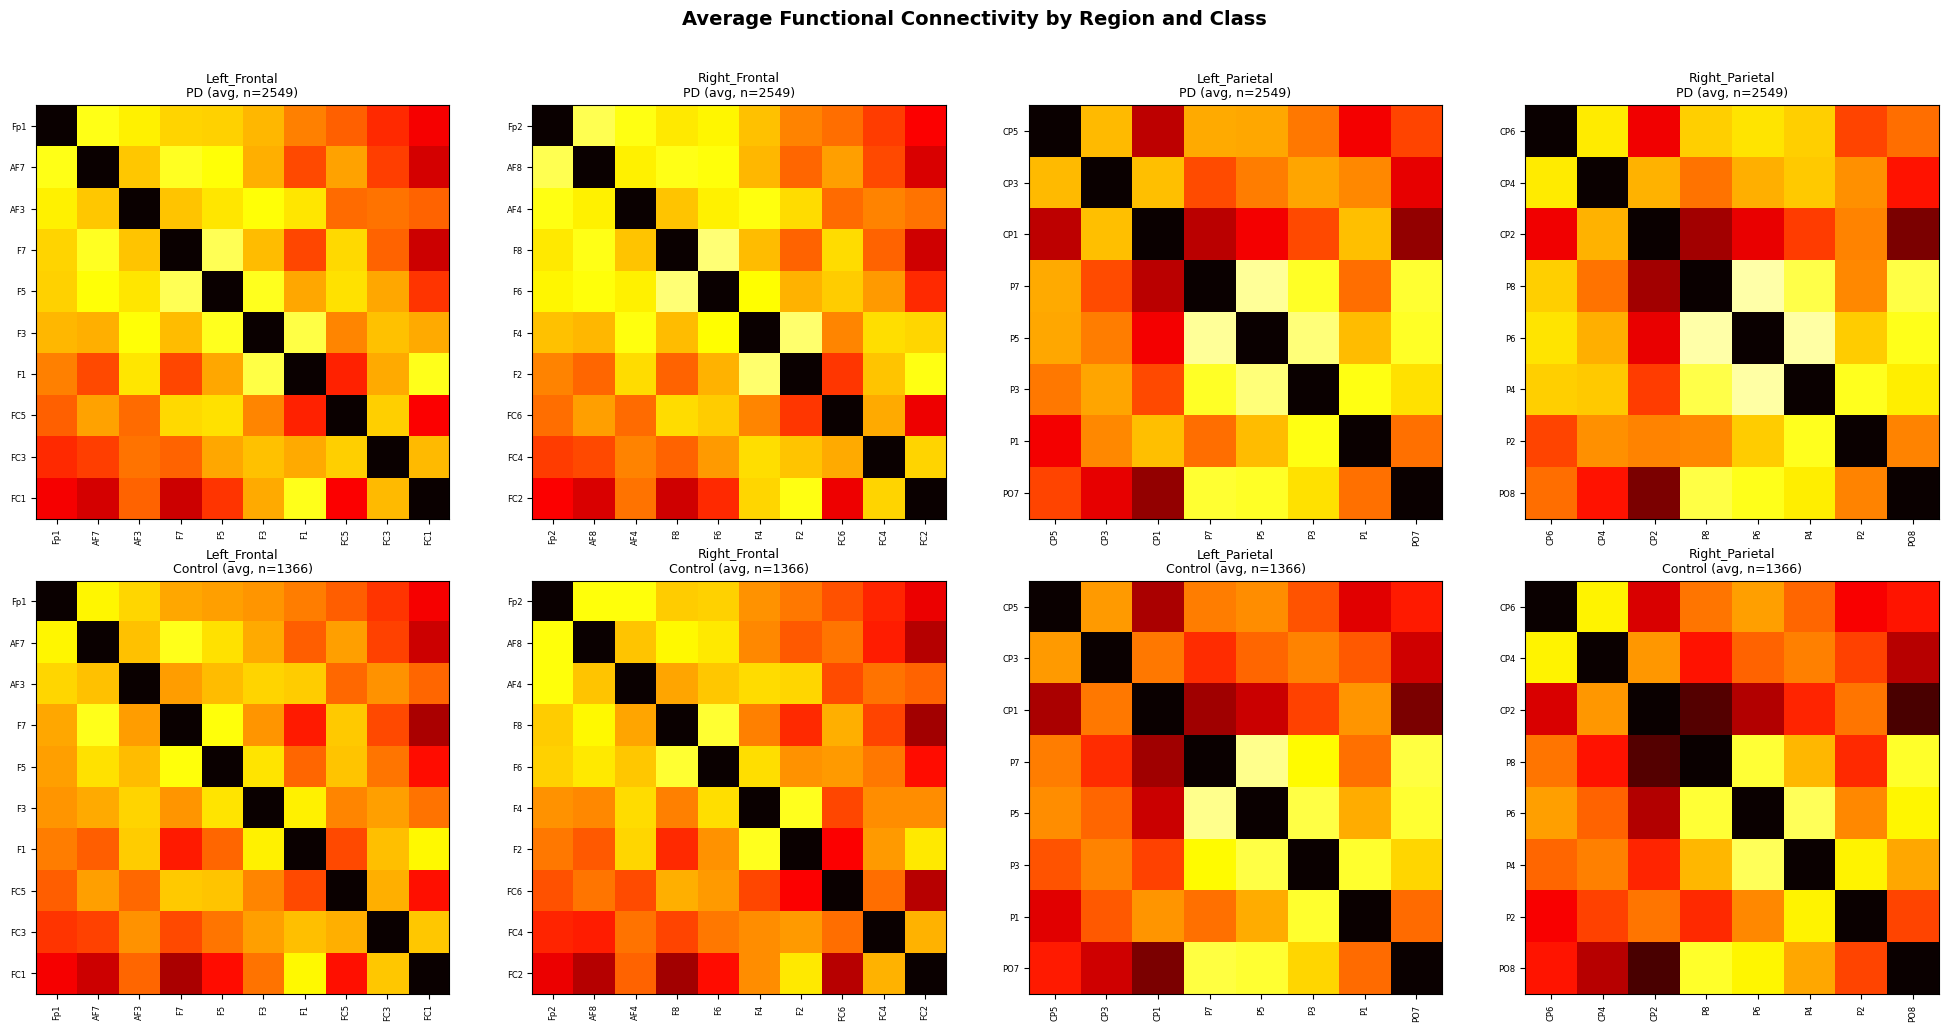

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

for col, region_name in enumerate(ROI_GROUPS):
    d = np.load(str(REGION_DIR / f'features_{region_name}.npz'), allow_pickle=True)
    adj, y_r = d['adjacency'], d['y']
    ch_names_r = list(d['channel_names'])

    for row, (cls, label) in enumerate([(1, 'PD'), (0, 'Control')]):
        avg_adj = adj[y_r == cls].mean(axis=0)
        im = axes[row, col].imshow(avg_adj, cmap='hot', vmin=0, vmax=1)
        axes[row, col].set_title(f'{region_name}\n{label} (avg, n={int((y_r==cls).sum())})', fontsize=9)
        axes[row, col].set_xticks(range(len(ch_names_r))); axes[row, col].set_xticklabels(ch_names_r, rotation=90, fontsize=6)
        axes[row, col].set_yticks(range(len(ch_names_r))); axes[row, col].set_yticklabels(ch_names_r, fontsize=6)

plt.suptitle('Average Functional Connectivity by Region and Class', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(str(REGION_DIR / 'regional_connectivity_heatmaps.png'), dpi=130, bbox_inches='tight')
plt.show()

# Cell 10 — Cohen's d heatmap: which features discriminate PD best, per region (the key analytical visual)

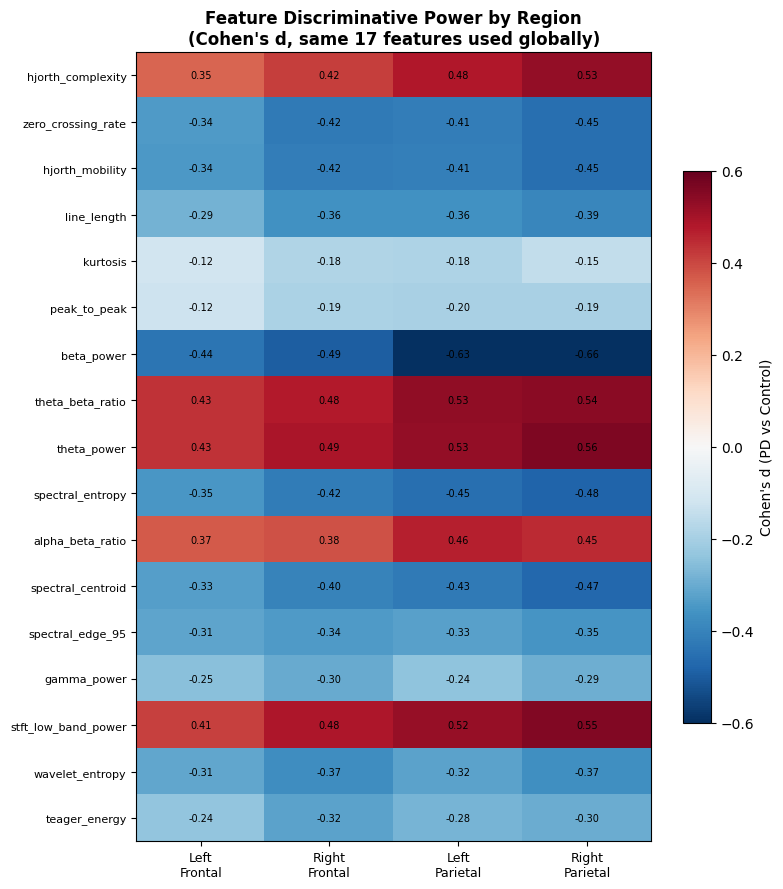

Strongest |d| per region:
  Left_Frontal: beta_power (d=-0.436)
  Right_Frontal: beta_power (d=-0.493)
  Left_Parietal: beta_power (d=-0.635)
  Right_Parietal: beta_power (d=-0.662)


In [10]:
def cohens_d(a, b):
    n1,n2 = len(a),len(b)
    v1,v2 = a.var(ddof=1), b.var(ddof=1)
    pooled = np.sqrt(((n1-1)*v1+(n2-1)*v2)/(n1+n2-2))
    return 0.0 if pooled < 1e-12 else (a.mean()-b.mean())/pooled

d_matrix = np.zeros((len(SELECTED_FEATURE_NAMES), len(ROI_GROUPS)))

for col, region_name in enumerate(ROI_GROUPS):
    d = np.load(str(REGION_DIR / f'features_{region_name}.npz'), allow_pickle=True)
    nf, y_r = d['node_features'], d['y']
    for row, feat_name in enumerate(SELECTED_FEATURE_NAMES):
        vals = nf[:,:,:,row].ravel()
        labels_full = np.repeat(y_r, nf.shape[1]*nf.shape[2])
        d_matrix[row, col] = cohens_d(vals[labels_full==1], vals[labels_full==0])

fig, ax = plt.subplots(figsize=(8, 9))
im = ax.imshow(d_matrix, cmap='RdBu_r', vmin=-0.6, vmax=0.6, aspect='auto')
ax.set_xticks(range(len(ROI_GROUPS))); ax.set_xticklabels([r.replace('_','\n') for r in ROI_GROUPS], fontsize=9)
ax.set_yticks(range(len(SELECTED_FEATURE_NAMES))); ax.set_yticklabels(SELECTED_FEATURE_NAMES, fontsize=8)
for i in range(d_matrix.shape[0]):
    for j in range(d_matrix.shape[1]):
        ax.text(j, i, f'{d_matrix[i,j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im, ax=ax, label="Cohen's d (PD vs Control)", shrink=0.7)
ax.set_title("Feature Discriminative Power by Region\n(Cohen's d, same 17 features used globally)",
            fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(str(REGION_DIR / 'regional_cohens_d_heatmap.png'), dpi=140, bbox_inches='tight')
plt.show()

print('Strongest |d| per region:')
for col, region_name in enumerate(ROI_GROUPS):
    best_idx = np.argmax(np.abs(d_matrix[:, col]))
    print(f'  {region_name}: {SELECTED_FEATURE_NAMES[best_idx]} (d={d_matrix[best_idx, col]:.3f})')